In [18]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

import verde as vd
import geopandas as gpd


Train and test size for random splits: 66376 16594
Train and test size for block splits:  66568 16402


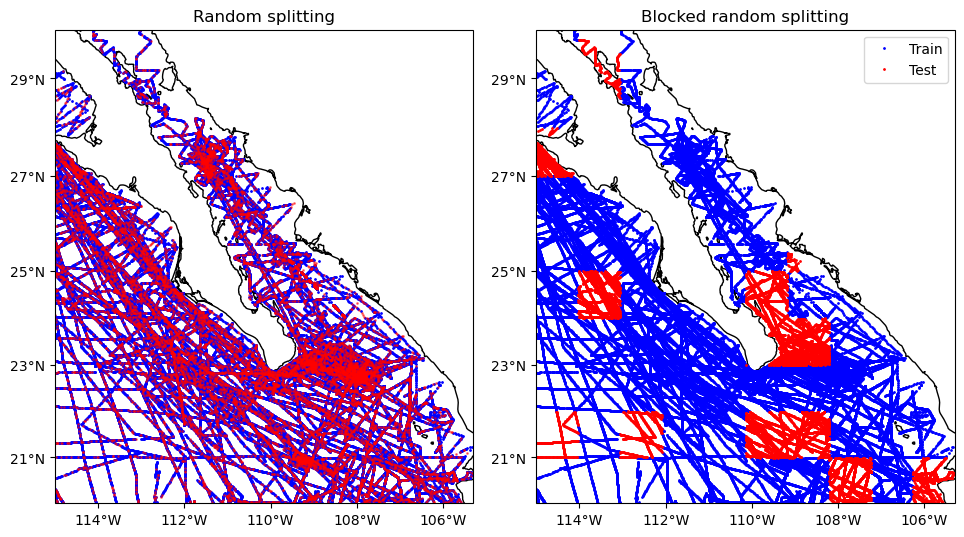

In [19]:
# Let's split the Baja California shipborne bathymetry data
data = vd.datasets.fetch_baja_bathymetry()
coordinates = (data.longitude, data.latitude)
values = data.bathymetry_m

# Assign 20% of the data to the testing set.
test_size = 0.2

# Split the data randomly into training and testing. Set the random state
# (seed) so that we get the same result if running this code again.
train, test = vd.train_test_split(
    coordinates, values, test_size=test_size, random_state=123
)
# train and test are tuples = (coordinates, data, weights).
print("Train and test size for random splits:", train[0][0].size, test[0][0].size)

# A different strategy is to first assign the data to blocks and then split the
# blocks randomly. To do this, specify the size of the blocks using the
# 'spacing' argument.
train_block, test_block = vd.train_test_split(
    coordinates,
    values,
    spacing=100 / 100,
    test_size=test_size,
    random_state=213,
)
# Verde will automatically attempt to balance the data between the splits so
# that the desired amount is assigned to the test set. It won't be exact since
# blocks contain different amounts of data points.
print(
    "Train and test size for block splits: ",
    train_block[0][0].size,
    test_block[0][0].size,
)

# Cartopy requires setting the coordinate reference system (CRS) of the
# original data through the transform argument. Their docs say to use
# PlateCarree to represent geographic data.
crs = ccrs.PlateCarree()

# Make Mercator maps of the two different ways of splitting
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 6), subplot_kw=dict(projection=ccrs.Mercator())
)

# Use an utility function to setup the tick labels and the land feature
vd.datasets.setup_baja_bathymetry_map(ax1)
vd.datasets.setup_baja_bathymetry_map(ax2)

ax1.set_title("Random splitting")
ax1.plot(*train[0], ".b", markersize=2, transform=crs, label="Train")
ax1.plot(*test[0], ".r", markersize=2, transform=crs, label="Test", alpha=0.5)

ax2.set_title("Blocked random splitting")
ax2.plot(*train_block[0], ".b", markersize=2, transform=crs, label="Train")
ax2.plot(*test_block[0], ".r", markersize=2, transform=crs, label="Test")
ax2.legend(loc="upper right")

plt.subplots_adjust(wspace=0.15, top=1, bottom=0, left=0.05, right=0.95)
plt.show()

In [17]:
train_block

((array([245.48972, 245.4971 , 245.49956, ..., 245.01026, 245.00681,
         245.00337]),
  array([26.99157, 26.98379, 26.98119, ..., 24.61271, 24.61633, 24.61995])),
 (array([-1089., -1148., -1142., ..., -3832., -3852., -3889.]),),
 (None,))

In [24]:
gdf = gpd.read_file('../data/tmp/subset_5k_per_class.gpkg')

In [28]:
gdf.geometry.y

0        -1.214073
1         6.055408
2         6.046245
3         5.597267
4         5.624755
           ...    
55411    10.758438
55412    -6.334443
55413    -5.749667
55414     3.154946
55415    -0.435234
Length: 55416, dtype: float64

Train and test size for random splits: 44332 11084
Train and test size for block splits:  44505 10911


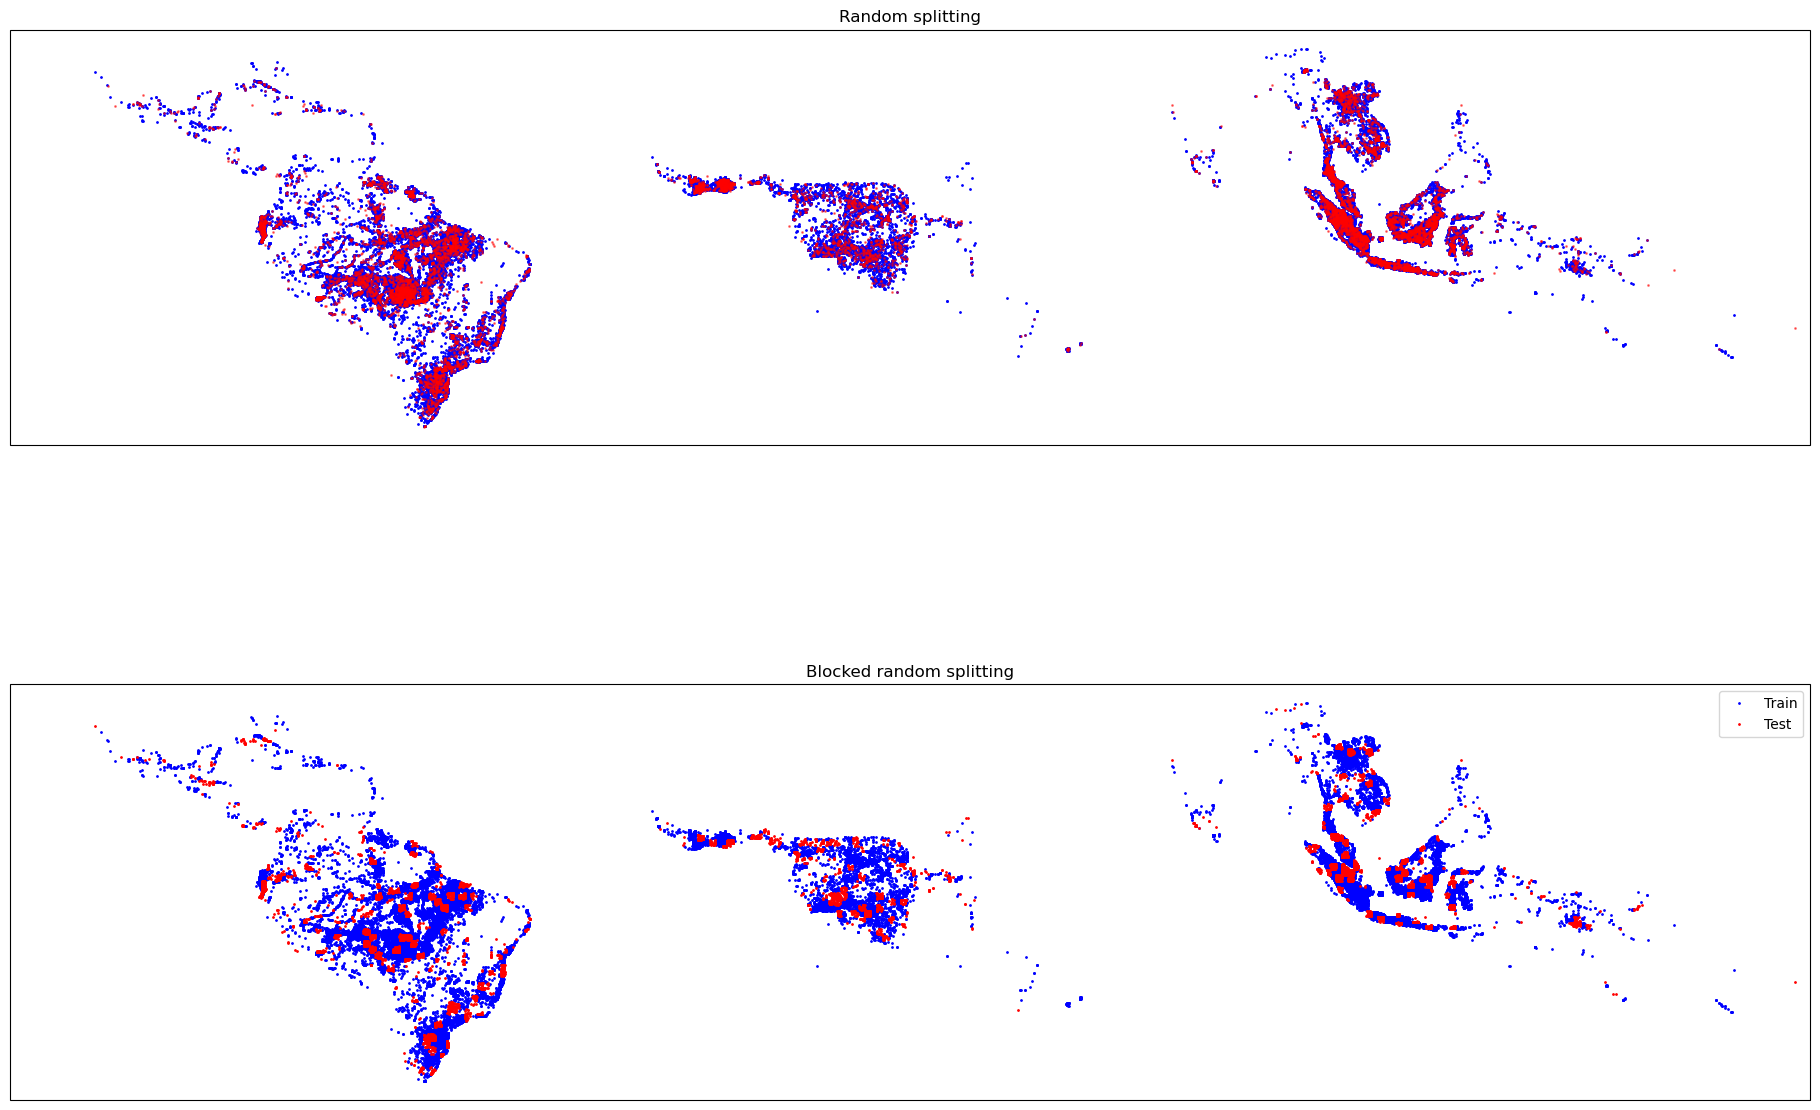

In [31]:
coordinates = (gdf.geometry.x, gdf.geometry.y)
values = gdf.index



# Assign 20% of the data to the testing set.
test_size = 0.2

# Split the data randomly into training and testing. Set the random state
# (seed) so that we get the same result if running this code again.
train, test = vd.train_test_split(
    coordinates, values, test_size=test_size, random_state=123
)
# train and test are tuples = (coordinates, data, weights).
print("Train and test size for random splits:", train[0][0].size, test[0][0].size)

# A different strategy is to first assign the data to blocks and then split the
# blocks randomly. To do this, specify the size of the blocks using the
# 'spacing' argument.
train_block, test_block = vd.train_test_split(
    coordinates,
    values,
    spacing=100 / 100,
    test_size=test_size,
    random_state=213,
)
# Verde will automatically attempt to balance the data between the splits so
# that the desired amount is assigned to the test set. It won't be exact since
# blocks contain different amounts of data points.
print(
    "Train and test size for block splits: ",
    train_block[0][0].size,
    test_block[0][0].size,
)

# Cartopy requires setting the coordinate reference system (CRS) of the
# original data through the transform argument. Their docs say to use
# PlateCarree to represent geographic data.
crs = ccrs.PlateCarree()

# Make Mercator maps of the two different ways of splitting
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(20, 12), subplot_kw=dict(projection=ccrs.Mercator())
)


ax1.set_title("Random splitting")
ax1.plot(*train[0], ".b", markersize=2, transform=crs, label="Train")
ax1.plot(*test[0], ".r", markersize=2, transform=crs, label="Test", alpha=0.5)

ax2.set_title("Blocked random splitting")
ax2.plot(*train_block[0], ".b", markersize=2, transform=crs, label="Train")
ax2.plot(*test_block[0], ".r", markersize=2, transform=crs, label="Test")
ax2.legend(loc="upper right")

plt.subplots_adjust(wspace=0.15, top=1, bottom=0, left=0.05, right=0.95)
plt.show()

In [32]:
train_block

((array([-80.06997419,  -3.25272692,  -1.83249046, ..., 106.68137672,
         -35.32238248, 101.7271908 ]),
  array([-1.2140731 ,  6.05540774,  6.04624492, ..., -6.33444276,
         -5.74966696, -0.43523375])),
 (Index([    0,     1,     2,     3,     4,     5,     8,     9,    13,    14,
         ...
         55405, 55406, 55407, 55408, 55409, 55410, 55411, 55412, 55413, 55415],
        dtype='int64', length=44505),),
 (None,))

[0,
 1,
 2,
 3,
 4,
 5,
 8,
 9,
 13,
 14,
 15,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 40,
 42,
 43,
 45,
 47,
 48,
 49,
 50,
 51,
 52,
 54,
 55,
 56,
 58,
 59,
 60,
 62,
 63,
 64,
 65,
 66,
 67,
 69,
 71,
 73,
 75,
 76,
 77,
 79,
 81,
 82,
 83,
 84,
 85,
 86,
 87,
 88,
 89,
 90,
 91,
 92,
 93,
 94,
 95,
 96,
 97,
 99,
 100,
 101,
 102,
 103,
 105,
 106,
 109,
 110,
 111,
 112,
 113,
 114,
 115,
 116,
 117,
 118,
 119,
 120,
 121,
 122,
 123,
 124,
 125,
 126,
 127,
 128,
 129,
 131,
 134,
 135,
 136,
 137,
 138,
 141,
 143,
 144,
 145,
 146,
 149,
 150,
 152,
 153,
 154,
 156,
 157,
 159,
 160,
 161,
 162,
 163,
 164,
 165,
 166,
 167,
 168,
 169,
 170,
 172,
 173,
 174,
 175,
 176,
 177,
 178,
 179,
 180,
 181,
 182,
 183,
 186,
 188,
 191,
 192,
 193,
 194,
 195,
 197,
 199,
 201,
 202,
 203,
 204,
 205,
 208,
 209,
 210,
 211,
 212,
 213,
 214,
 215,
 216,
 217,
 218,
 225,
 226,
 227,
 228,
 229,
 231,
 233,
 234,
 

In [42]:

gdf['split'] = None

In [47]:

gdf['split'] = None
gdf.loc[gdf.index.isin(train_block[1][0]), 'split'] = 'train'
gdf.loc[~gdf.index.isin(train_block[1][0]), 'split'] = 'test'

In [49]:
fagdf.loc[~gdf.index.isin(train_block[1][0]), 'split'] = 'test'

In [50]:
gdf.to_file('../data/tmp/split.gpkg')